# 01 · Currency, USD amount and business vs consumer behaviour
**Owner:** Chan Jia Yi · **Needs:** run `04_integration_validation.ipynb` first (it builds `data/processed/`).

Three feature groups, one dashboard each. Rule IDs match `outputs/tables/rules_log.csv`, the charts and the slides. Every chart title states the rule.
The test statistics and verdicts for each rule are in notebook 04 (section 3).

| Group | Rules |
|---|---|
| Currency | R-CCY1 to R-CCY3 |
| USD amount | R-AMT1 to R-AMT3, plus rejected hypotheses N1 to N4 |
| Business vs consumer | R-BC1 to R-BC4 |

*Country* = bank (BIC) country. *Local currency* = the currency a country's senders use most, inferred from this data.

### Evidence policy (updated 18 Nov 2026)
- **One verdict system, two kinds of rule** (column `verdict_basis` in `evidence_matrix.csv`):
  - *Accuracy rules* state a deterministic prediction (e.g. "Direct ⇔ 2 banks"). They are graded by the share of tested rows that obey them: `Confirmed` ≥ 99% · `Strong` 95–99% · `Partial` 70–95% · `Weak` below that. The tested denominator and any exclusions are always shown.
  - *Effect rules* state a size, an independence or a distribution (e.g. "×7.4 per business party").
    - `Supported`: the stated effect holds **and** the out-of-sample (holdout) estimate agrees with it, by the criterion written in `holdout_rule`, e.g. overlapping 95% CIs.
    - `Approximate`: the direction is right, but the holdout disagrees, is missing, or the model misses. The reason is in `verdict_note`.
    - `Rejected` or `Inconclusive` otherwise.
- **Causal status** says how far the evidence goes. It describes the evidence, not proof of the generator's code.
  - `Mechanism`: needs a 95% CI, an out-of-sample check, a subgroup check and a practical meaning. Rules lacking any of these are automatically downgraded.
  - `Association`: a real, stable pattern whose cause is not identified.
  - `Structural`: true by how the fields are defined.
  - `Rejected`: the stated prediction fails.
  - `Unresolved`: the tested method found no support but cannot rule the mechanism out.
- **Interpretations** ("consistent with …", "plausibly …") are possible explanations, not proven causes. "No measurable association" is not proof of independence, and "no detectable difference" is not proof that something is random.
- **Local time** uses clock offsets inferred from the CSV under stated assumptions (Monday–Friday week, no summer time, one offset per country). They are not verified time zones, and office-hour results on that clock are partly built into the offsets.
- **READY** (end of notebook 04) means every file comes from the current code and data, and every required piece of evidence is present and consistent. It does not prove that a rule is the generator's actual code.
- **Accounts** are always identified by **(BIC8, account number)**, because 2.4% of receiver account numbers recur at several banks.
- **Data used:** only the organiser CSV. Local currency and each country's clock offset are **inferred from the CSV itself**; the clock offsets come from the training period only. No time-zone database, currency table or GDP data enters any calculation.
- Saved outputs are cleared in this pack. Re-run in the order 04 → 01 → 02 → 03 → 04 before quoting any number.

In [1]:
from pathlib import Path
import os, warnings; warnings.filterwarnings('ignore')
import duckdb, numpy as np, pandas as pd
import matplotlib.pyplot as plt
pd.set_option('display.width', 220); pd.set_option('display.max_columns', 60)

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
RAW, PROC = ROOT / 'data' / 'raw', ROOT / 'data' / 'processed'
FIG, TAB = ROOT / 'outputs' / 'figures', ROOT / 'outputs' / 'tables'
RULES = TAB / 'rules'                       # one rules file per notebook -> combined into outputs/tables/rules_log.csv
for d in (RAW, PROC, FIG, TAB, RULES): d.mkdir(parents=True, exist_ok=True)
FULL    = PROC / 'payments_clean.parquet'   # all 10M rows (nothing removed) + derived columns, built by notebook 04
SAMPLE  = PROC / 'sample_20pct.parquet'     # 20% Bernoulli sample (seed 42), no free-text columns, still includes anomalies
ANOM    = PROC / 'anomalies.parquet'        # every labelled anomaly row, all columns
SCHEMA_VERSION = '2'                        # bump when derived columns change -> notebook 04 rebuilds the files

def connect(db=':memory:'):
    con = duckdb.connect(str(db))
    con.execute("SET TimeZone='UTC'")       # never skip: otherwise DuckDB shows laptop time (+08)
    con.execute("SET preserve_insertion_order=false")
    try: con.execute("SET enable_progress_bar=false")   # no progress widgets saved in the notebook ("Could not render ... widget" in viewers)
    except Exception: pass                           # (older setups without ipywidgets show no widget anyway)
    con.execute(f"SET temp_directory='{(PROC / 'duck_tmp').as_posix()}'")   # big joins spill to disk instead of crashing
    if os.environ.get('SWIFT_MEMORY'):  con.execute(f"SET memory_limit='{os.environ['SWIFT_MEMORY']}'")   # e.g. 4GB on an 8 GB laptop
    if os.environ.get('SWIFT_THREADS'): con.execute(f"SET threads={int(os.environ['SWIFT_THREADS'])}")
    return con

In [2]:
con = connect()

In [3]:
def sql(q):
    """Run SQL on the full data and return a pandas DataFrame."""
    return con.execute(q).df()
q = sql
def save_table(df, name):
    """Save a result table to outputs/tables/<name>.csv and return it for display."""
    df.to_csv(TAB / f'{name}.csv', index=False); return df

RULE_COLS = ['id', 'group', 'rule', 'test', 'value', 'verdict', 'evidence_files', 'interpretation']
VERDICTS = 'Confirmed (holds in >=99% of rows / effect matches) · Strong (95-99%) · Partial (70-95% or only in a subgroup) · Weak (<70%) · Rejected (prediction fails)'
def verdict_from_share(x):
    return 'Confirmed' if x >= 0.99 else 'Strong' if x >= 0.95 else 'Partial' if x >= 0.70 else 'Weak'

def combine_rules():
    """Combine standardized teammate rule tables and flag unfinished placeholders.

    Running notebook 04 *first* creates its core rules; re-run the final
    consolidation cell after notebooks 01-03 to capture every teammate's work.
    """
    frames = []
    for f in sorted(RULES.glob('rules_*.csv')):
        d = pd.read_csv(f)
        aliases = {'observed_evidence_table_or_chart': 'evidence_files',
                   'interpretation_real_world': 'interpretation', 'confidence': 'verdict'}
        d = d.rename(columns={a:b for a,b in aliases.items() if a in d and b not in d})
        if 'rule' not in d and {'when_condition', 'then_effect'} <= set(d.columns):
            d['rule'] = d['when_condition'].fillna('') + ' -> ' + d['then_effect'].fillna('')
        if 'value' not in d and 'size' in d: d['value'] = d['size']
        for col in RULE_COLS:
            if col not in d: d[col] = ''
        d['source'] = f.name
        frames.append(d)
    out = pd.concat(frames, ignore_index=True) if frames else pd.DataFrame(columns=RULE_COLS+['source'])
    required = {'rules_04_core.csv','rules_02.csv','rules_03_anomalies.csv'}
    missing = sorted(required - {f.name for f in RULES.glob('rules_*.csv')})
    dup = out['id'].astype(str).duplicated(keep=False) if len(out) else []
    unfinished = out.astype(str).apply(lambda col: col.str.contains(r'TODO|\?\?|A2-example', case=False, regex=True)).any(axis=1) if len(out) else []
    if missing: print('INTEGRATION INCOMPLETE — missing:', ', '.join(missing))
    if len(out) and any(dup): print('INTEGRATION WARNING — repeated rule IDs:', out.loc[dup,'id'].tolist())
    if len(out) and any(unfinished): print('INTEGRATION WARNING — unresolved template cells:', out.loc[unfinished,'id'].tolist())
    out = out[ RULE_COLS + ['source'] + [c for c in out if c not in RULE_COLS + ['source']] ]
    out.to_csv(TAB/'rules_log.csv', index=False)
    return out

In [4]:
# Main view `p` = full data with the shared derived columns (see notebook 04, section 1)
assert FULL.exists() and (PROC / '_schema_version.txt').exists() and (PROC / '_schema_version.txt').read_text().strip() == SCHEMA_VERSION, \
    'Shared data missing or outdated: run notebooks/04_integration_validation.ipynb first'
con.execute(f"CREATE OR REPLACE VIEW p AS SELECT * FROM read_parquet('{FULL.as_posix()}')")
# Local currency of each BIC country = the currency its senders use most (inferred from this dataset, no external lookup)
con.execute("""CREATE OR REPLACE TABLE local_ccy AS
  SELECT o_cc AS cc, arg_max(CURRENCY_CODE, n) AS local_ccy FROM
  (SELECT o_cc, CURRENCY_CODE, count(*) n FROM p GROUP BY ALL) GROUP BY o_cc""")
print(f"{con.execute('SELECT count(*) FROM p').fetchone()[0]:,} payments loaded")

10,000,000 payments loaded


In [5]:
# Evidence toolkit (identical in every notebook): 95% CIs, tests, a time-based train/test split and causal labels
from scipy import stats
EVID_COLS = ['id', 'statistic_ci', 'p_value', 'out_of_sample', 'invariance', 'causal_status', 'practical_significance',
             'holdout_agrees', 'holdout_rule']   # holdout_agrees: does the out-of-sample estimate agree with the stated effect / CI?
CAUSAL = {   # how strongly a rule is a cause-and-effect rule of the generator (used in every evidence_*.csv)
    'Mechanism':   'consistent with a generator rule: holds after controls, out of sample and in every subgroup tested, and a placebo / '
                   'negative control shows no effect (supported by the data, not proof of the generator code)',
    'Structural':  'true by how the fields are built (a definition or an accounting identity), not a behavioural finding',
    'Association': 'real and stable pattern, but the data cannot show why: an unobserved cause is possible',
    'Rejected':    'the stated prediction fails, or the pattern is explained away by a confounder',
    'Unresolved':  'the tested method found no support, but it cannot rule the mechanism out (e.g. matching may miss links)'}
# A rule may be called 'Mechanism' only with ALL of these filled in; notebook 04 downgrades it to 'Association' otherwise
MECHANISM_NEEDS = ['statistic_ci', 'out_of_sample', 'invariance', 'practical_significance']

def wilson(k, n, z=1.96):
    """95% Wilson score interval for a share k/n (stays inside 0-100%, works for 0% and 100%)."""
    if not n: return np.nan, np.nan
    p = k / n; d = 1 + z * z / n; c = (p + z * z / (2 * n)) / d
    h = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / d
    return max(0.0, c - h), min(1.0, c + h)

def share_ci(k, n, digits=2):
    """'97.80% [97.78%, 97.82%], n = 1,234' for a share k/n."""
    if not n: return 'n = 0'
    lo, hi = wilson(k, n); f = f'{{:.{digits}%}}'
    return f'{f.format(k / n)} [{f.format(lo)}, {f.format(hi)}], n = {int(n):,}'

def two_prop(k1, n1, k2, n2):
    """Share difference (group 1 - group 2), its 95% CI and a two-sided z-test p-value."""
    if not n1 or not n2: return np.nan, (np.nan, np.nan), np.nan
    p1, p2 = k1 / n1, k2 / n2; pp = (k1 + k2) / (n1 + n2)
    se0 = np.sqrt(pp * (1 - pp) * (1 / n1 + 1 / n2)); se = np.sqrt(p1 * (1 - p1) / n1 + p2 * (1 - p2) / n2)
    pval = 2 * stats.norm.sf(abs(p1 - p2) / se0) if se0 > 0 else (0.0 if p1 != p2 else 1.0)
    return p1 - p2, (p1 - p2 - 1.96 * se, p1 - p2 + 1.96 * se), pval

def paired_prop(a, b):
    """Two yes/no outcomes measured on the SAME rows (e.g. office hour on local clock vs UTC): McNemar test.
    Returns share(a) - share(b), its 95% CI and the p-value; only the discordant rows carry information."""
    a, b = np.asarray(a, bool), np.asarray(b, bool); n = len(a)
    n10, n01 = int((a & ~b).sum()), int((~a & b).sum()); d = (n10 - n01) / n
    se = np.sqrt(max(n10 + n01 - (n10 - n01) ** 2 / n, 0)) / n
    pval = stats.binomtest(n10, n10 + n01).pvalue if 0 < n10 + n01 < 1000 else (2 * stats.norm.sf(abs(n10 - n01) / np.sqrt(n10 + n01)) if n10 + n01 else 1.0)
    return d, (d - 1.96 * se, d + 1.96 * se), pval

def cramers_v_ct(ct):
    ct = np.asarray(ct, float); chi2 = stats.chi2_contingency(ct)[0]
    return np.sqrt(chi2 / (ct.sum() * (min(ct.shape) - 1)))

def v_ci(ct, reps=200, seed=0):
    """Cramér's V with a 95% CI (multinomial bootstrap of the contingency table)."""
    ct = np.asarray(ct, float); rng = np.random.default_rng(seed); n = int(ct.sum())
    boot = [cramers_v_ct(rng.multinomial(n, (ct / n).ravel()).reshape(ct.shape) + 1e-9) for _ in range(reps)]
    return cramers_v_ct(ct), np.percentile(boot, [2.5, 97.5])

def fmt_p(p):
    if p is None or not np.isfinite(p): return 'p = n/a'
    return 'p < 1e-300' if p == 0 else f'p = {p:.1e}' if p < 1e-3 else f'p = {p:.3f}'

def median_ci(x):
    """Distribution-free 95% CI of a median from order statistics (no bootstrap needed)."""
    x = np.sort(np.asarray(x)); n = len(x)
    if n == 0: return np.nan, np.nan
    h = 1.96 * np.sqrt(n) / 2
    return x[max(0, int(np.floor(n / 2 - h)))], x[min(n - 1, int(np.ceil(n / 2 + h)))]

# Out-of-sample check by TIME: a rule is fitted on the first 2/3 of the data window and re-tested on the last 1/3
T_SPLIT = int(con.execute("SELECT quantile_disc(EPOCH_SECONDS, 2/3) FROM p").fetchall()[0][0])
print('train = before', pd.to_datetime(T_SPLIT, unit='s'), 'UTC; test = after')

import hashlib, json as _json
def code_hash(prefix):
    """Fingerprint of a notebook's CODE cells as saved on disk (outputs ignored): proves which code version made a file."""
    f = sorted((ROOT / 'notebooks').glob(f'{prefix}_*.ipynb'))
    if not f: return ''
    cells = _json.loads(f[0].read_text(encoding='utf-8'))['cells']
    return hashlib.sha1('\n'.join(''.join(c['source']) for c in cells if c['cell_type'] == 'code').encode()).hexdigest()[:12]
DATA_STAMP = f"{FULL.stat().st_size}-{int(FULL.stat().st_mtime)}"      # identifies the data build the results came from

def overlap(a, b):
    """True if two intervals (lo, hi) overlap: used to say a holdout estimate agrees with the full-data estimate."""
    return bool(max(a[0], b[0]) <= min(a[1], b[1]))
def holdout(ok, rule):
    return dict(holdout_agrees=bool(ok), holdout_rule=rule)

def save_evidence(rows, name):
    """rows: dicts with EVID_COLS -> outputs/tables/rules/evidence_<name>.csv (merged into the evidence matrix by notebook 04).
    Each file also records the code version (code_hash) and the data build (data_stamp) it came from."""
    e = pd.DataFrame(rows).reindex(columns=EVID_COLS)
    e['code_hash'], e['data_stamp'] = code_hash(name), DATA_STAMP
    bad = set(e.causal_status.dropna()) - set(CAUSAL)
    assert not bad, f'unknown causal_status {bad}'
    e.to_csv(RULES / f'evidence_{name}.csv', index=False); return e

train = before 2023-06-28 12:22:04 UTC; test = after


In [6]:
# Chart style (colour-blind-safe palette; text never in series colour)
C = {'B2B': '#2a78d6', 'B2C': '#eb6834', 'C2B': '#1baf7a', 'C2C': '#eda100', 'B': '#2a78d6', 'C': '#eb6834'}
GREY, TP, TS, GR = '#c3c2b7', '#0b0b0b', '#52514e', '#e4e3df'
plt.rcParams.update({'font.size': 10, 'axes.edgecolor': GR, 'axes.labelcolor': TS, 'xtick.color': TS, 'ytick.color': TS,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.color': GR, 'grid.linewidth': 0.6,
    'axes.axisbelow': True, 'axes.titlesize': 11, 'axes.titlecolor': TP, 'figure.facecolor': 'white', 'legend.frameon': False})
def save(fig, name, note=None):
    if note: fig.text(0.01, 0.005, note, fontsize=8, color=TS)
    fig.tight_layout(rect=(0, 0.04 if note else 0, 1, 1)); fig.savefig(FIG / name, dpi=160); plt.show()

In [7]:
# Sender-local time from clock offsets INFERRED FROM THE DATA (notebook 04, section 1b): no external time-zone table is used
CLK = PROC / 'clock_offsets.csv'
assert CLK.exists(), 'clock_offsets.csv missing: run notebooks/04_integration_validation.ipynb first'
OFFSET_H = pd.read_csv(CLK, keep_default_na=False, na_values=['']).set_index('cc').offset_hours   # keep_default_na: 'NA' = Namibia
def add_local_time(df, cc_col='o_cc', offsets=None):
    """Adds sender-local hour (lh) and weekday (ld, 0 = Mon). -1 where the country had too few rows to infer an offset."""
    off = df[cc_col].map(OFFSET_H if offsets is None else offsets)
    t = df['EPOCH_SECONDS'].values + (off.fillna(0).values * 3600).astype('int64')
    lh = (t // 3600) % 24; ld = (t // 86400 + 3) % 7              # 1970-01-01 was a Thursday -> +3 makes 0 = Monday
    ok = off.notna().values
    return df.assign(lh=np.where(ok, lh, -1), ld=np.where(ok, ld, -1))
print(f'{len(OFFSET_H)} countries with an inferred clock offset')

186 countries with an inferred clock offset


In [8]:
# Modelling sample: normal (non-anomaly) payments from the 20% sample
n = pd.read_parquet(SAMPLE, columns=['EPOCH_SECONDS','CURRENCY_CODE','USD_AMOUNT','o_cc','b_cc','ORDERING_TYPE','BENEFICIARY_TYPE',
        'pair','anomaly','ORDERING_BIC8','ORDERING_ACCOUNT','TRANSACTION_TYPE_CODE','CURRENCY_CONVERSION_COUNT','PARTICIPANT_COUNT'])
n = n[n.anomaly == 'NONE'].reset_index(drop=True)
n['la'] = np.log(n.USD_AMOUNT)                                   # ln(amount)
n['ob'] = (n.ORDERING_TYPE == 'B').astype(float)                 # sender is business
n['bb'] = (n.BENEFICIARY_TYPE == 'B').astype(float)              # receiver is business
loc = sql('SELECT * FROM local_ccy').set_index('cc').local_ccy
print(f'{len(n):,} normal payments in the modelling sample')

2,000,487 normal payments in the modelling sample


## 1. Currency
**Hypothesis:** the payment currency is decided by the **sender's** country, not the receiver's.

In [9]:
ccy = sql("SELECT CURRENCY_CODE, count(*) n, median(USD_AMOUNT) median_usd FROM p GROUP BY 1 ORDER BY 2 DESC")
ccy['share'] = ccy.n / ccy.n.sum(); ccy.to_csv(TAB / 'ccy_counts.csv', index=False)
print(len(ccy), 'currencies;', f"top 5 = {ccy.share.head(5).sum():.1%} of payments"); ccy.head(10)

155 currencies; top 5 = 69.5% of payments


,CURRENCY_CODE,n,median_usd,share
0,EUR,3198639,4603.620,0.319864
1,USD,1702991,6373.370,0.170299
2,GBP,873781,3586.120,0.087378
3,CHF,803898,6098.550,0.080390
4,SGD,367648,6404.805,0.036765
5,CNY,324963,1347.220,0.032496
6,HKD,197458,4892.975,0.019746
7,JPY,184251,2812.370,0.018425
8,AUD,166877,4623.230,0.016688
9,CAD,111146,4706.400,0.011115


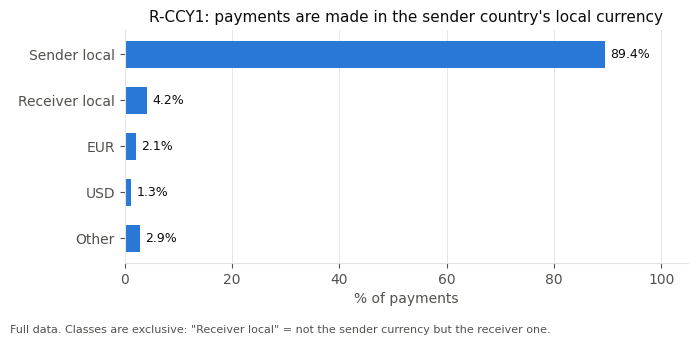

In [10]:
cls = sql("""SELECT CASE WHEN CURRENCY_CODE = ls.local_ccy THEN 'Sender local'
                         WHEN CURRENCY_CODE = lr.local_ccy THEN 'Receiver local'
                         WHEN CURRENCY_CODE IN ('EUR','USD') THEN CURRENCY_CODE ELSE 'Other' END AS cls, count(*) n
             FROM p LEFT JOIN local_ccy ls ON p.o_cc = ls.cc LEFT JOIN local_ccy lr ON p.b_cc = lr.cc GROUP BY 1""").set_index('cls').n
s = (cls / cls.sum() * 100).reindex(['Sender local', 'Receiver local', 'EUR', 'USD', 'Other']).fillna(0)
s.to_csv(TAB / 'ccy1_currency_choice.csv', header=['pct'])
fig, ax = plt.subplots(figsize=(7, 3.4)); bars = ax.barh(s.index[::-1], s.values[::-1], color=C['B'], height=0.6)
for r, v in zip(bars, s.values[::-1]): ax.text(v + 1, r.get_y() + r.get_height() / 2, f'{v:.1f}%', va='center', fontsize=9, color=TP)
ax.set_xlim(0, 105); ax.set_xlabel('% of payments'); ax.grid(axis='y', visible=False)
ax.set_title("R-CCY1: payments are made in the sender country's local currency")
save(fig, 'ccy1_currency_choice.png', 'Full data. Classes are exclusive: "Receiver local" = not the sender currency but the receiver one.')

In [11]:
# R-CCY1 follow-up (full data): is the payment currency set by the ORDERING bank or by the FIRST BANK ON THE PATH?
# They differ in ~5% of rows (R-RT2). 'Local' = the dataset's modal currency per bank country, not an external currency table.
ccy_evidence = save_table(sql("""
SELECT count(*) AS tested_rows,
       avg((CURRENCY_CODE = lo.local_ccy)::INT) AS ordering_bank_match,
       avg((CURRENCY_CODE = lf.local_ccy)::INT) AS first_path_bank_match,
       avg((split_part(BIC8_PATH, ';', 1) <> ORDERING_BIC8)::INT) AS first_bank_differs
FROM p LEFT JOIN local_ccy lo ON p.o_cc = lo.cc
       LEFT JOIN local_ccy lf ON substr(split_part(p.BIC8_PATH, ';', 1), 5, 2) = lf.cc"""), 'ccy1_ordering_vs_first_bank')
display(ccy_evidence); ccy_evidence = ccy_evidence.iloc[0]

,tested_rows,ordering_bank_match,first_path_bank_match,first_bank_differs
0,10000000,0.894479,0.934157,0.04984


### Currency holdout check (avoids in-sample mode leakage)
Because the *local* currency is inferred as the most-used currency in each BIC country from this same CSV, evaluating the rule on the entire data can inflate fit. This follow-up learns modal currencies using **80% of records** (deterministic hash split) and evaluates them on **disjoint 20%**. Report both holdout accuracy and the fraction of test rows with an inferred mapping. This is a reproducible internal validation, not an external currency lookup.

In [12]:
# Purely organizer-data holdout: train country modes on 80%, evaluate on a non-overlapping 20%.
ccy_holdout = sql("""
WITH train_counts AS (
 SELECT o_cc AS cc, CURRENCY_CODE, count(*) n FROM p
 WHERE hash(rid) % 5 <> 0 GROUP BY 1,2
), modes AS (
 SELECT cc, arg_max(CURRENCY_CODE,n) AS inferred_ccy FROM train_counts GROUP BY cc
), test AS (
 SELECT p.CURRENCY_CODE, p.o_cc,
        substr(split_part(p.BIC8_PATH,';',1),5,2) AS first_cc
 FROM p WHERE hash(rid) % 5 = 0
)
SELECT count(*) AS holdout_rows,
       sum((lo.inferred_ccy IS NOT NULL)::INT) AS ordering_mapped_rows,
       sum((lf.inferred_ccy IS NOT NULL)::INT) AS first_mapped_rows,
       avg(CASE WHEN lo.inferred_ccy IS NOT NULL THEN (t.CURRENCY_CODE = lo.inferred_ccy)::INT END) AS ordering_accuracy_mapped,
       avg(CASE WHEN lf.inferred_ccy IS NOT NULL THEN (t.CURRENCY_CODE = lf.inferred_ccy)::INT END) AS first_path_accuracy_mapped
FROM test t
LEFT JOIN modes lo ON t.o_cc = lo.cc
LEFT JOIN modes lf ON t.first_cc = lf.cc
""")
display(save_table(ccy_holdout, 'ccy1_train80_test20'))
print('Use holdout accuracy (not the in-sample rate) for the strongest claim in final slides.')

,holdout_rows,ordering_mapped_rows,first_mapped_rows,ordering_accuracy_mapped,first_path_accuracy_mapped
0,2002540,2002540.0,2002540.0,0.894863,0.934361


Use holdout accuracy (not the in-sample rate) for the strongest claim in final slides.


**Hypothesis:** a conversion happens when money moves between two currency areas. A **Direct** payment (2 banks) should be converted exactly once if the two local currencies differ, and not at all otherwise.

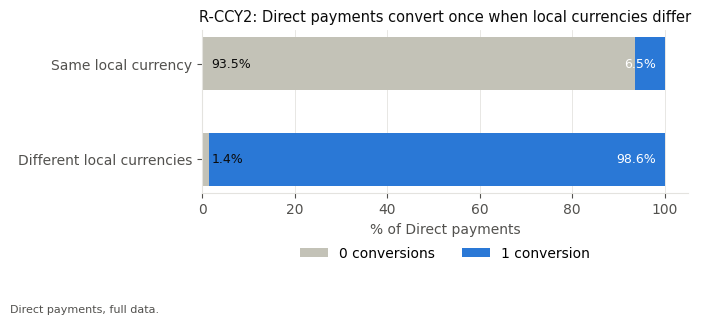

In [13]:
cv = sql("""SELECT CASE WHEN ls.local_ccy = lr.local_ccy THEN 'Same local currency' ELSE 'Different local currencies' END grp,
            CURRENCY_CONVERSION_COUNT k, count(*) n
            FROM p LEFT JOIN local_ccy ls ON p.o_cc = ls.cc LEFT JOIN local_ccy lr ON p.b_cc = lr.cc
            WHERE TRANSACTION_TYPE_CODE = 'Direct' GROUP BY ALL""").pivot(index='grp', columns='k', values='n').fillna(0)
t = cv.div(cv.sum(1), axis=0) * 100; t.to_csv(TAB / 'ccy2_direct_conversions.csv')
fig, ax = plt.subplots(figsize=(7, 3.2)); y = np.arange(len(t))
ax.barh(y, t[0], color=GREY, height=0.55, label='0 conversions'); ax.barh(y, t[1], left=t[0], color=C['B'], height=0.55, label='1 conversion')
for i, (a, b) in enumerate(zip(t[0], t[1])):
    ax.text(2, i, f'{a:.1f}%', va='center', fontsize=9, color=TP); ax.text(98, i, f'{b:.1f}%', va='center', ha='right', fontsize=9, color='white')
ax.set_yticks(y, t.index); ax.set_xlabel('% of Direct payments'); ax.grid(axis='y', visible=False)
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.25), ncol=2)
ax.set_title('R-CCY2: Direct payments convert once when local currencies differ', fontsize=10.5)
save(fig, 'ccy2_direct_conversion_rule.png', 'Direct payments, full data.')

In [14]:
# R-CCY3: conversions vs hops on multi-bank routes
hop = sql("""SELECT PARTICIPANT_COUNT - 1 AS hops, CURRENCY_CONVERSION_COUNT conv, count(*) n FROM p
             WHERE TRANSACTION_TYPE_CODE <> 'Direct' AND PARTICIPANT_COUNT <= 6 GROUP BY ALL""")
ht = hop.pivot(index='hops', columns='conv', values='n').fillna(0); ht = (ht.div(ht.sum(1), axis=0) * 100).round(1)
ht.to_csv(TAB / 'ccy3_conversions_by_hops.csv'); print('% of payments by number of conversions (columns) for each hop count (rows):'); ht

% of payments by number of conversions (columns) for each hop count (rows):


conv,0,1,2,3,4,5
hops,,,,,,
2,3.7,21.7,74.6,0.0,0.0,0.0
3,1.0,6.2,29.0,63.8,0.0,0.0
4,0.3,1.8,10.0,32.8,55.1,0.0
5,0.1,0.5,3.4,13.2,35.2,47.5


In [15]:
# Evidence (currency): 95% CIs, stability by month, out-of-sample test, a negative control and the money involved.
# Out of sample: each country's local currency is re-learned on the first 2/3 of the time window only, then the rules
# are scored on the last 1/3. Negative control: the RECEIVER's party type should not change the currency choice.
cur = sql(f"""
WITH tr AS (SELECT o_cc AS cc, arg_max(CURRENCY_CODE, n) AS local_ccy FROM
            (SELECT o_cc, CURRENCY_CODE, count(*) n FROM p WHERE EPOCH_SECONDS < {T_SPLIT} GROUP BY ALL) GROUP BY o_cc)
SELECT strftime(p.ts, '%Y-%m') AS month, p.EPOCH_SECONDS >= {T_SPLIT} AS test, p.BENEFICIARY_TYPE AS b_type,
       count(*) AS n,
       sum((CURRENCY_CODE = ls.local_ccy)::INT)                                             AS k1,
       sum((CURRENCY_CODE = ts.local_ccy)::INT)                                             AS k1_trained,
       sum((TRANSACTION_TYPE_CODE = 'Direct')::INT)                                         AS n_direct,
       sum((TRANSACTION_TYPE_CODE = 'Direct' AND CURRENCY_CONVERSION_COUNT = (ls.local_ccy <> lr.local_ccy)::INT)::INT) AS k2,
       sum((TRANSACTION_TYPE_CODE = 'Direct' AND CURRENCY_CONVERSION_COUNT = (ts.local_ccy <> tb.local_ccy)::INT)::INT) AS k2_trained,
       sum((CURRENCY_CONVERSION_COUNT <= PARTICIPANT_COUNT - 1)::INT)                       AS k3,
       sum(USD_AMOUNT) AS usd,
       sum(CASE WHEN CURRENCY_CODE <> ls.local_ccy THEN USD_AMOUNT ELSE 0 END)              AS usd_nonlocal,
       sum(CASE WHEN CURRENCY_CONVERSION_COUNT > 0 THEN USD_AMOUNT ELSE 0 END)              AS usd_converted
FROM p LEFT JOIN local_ccy ls ON p.o_cc = ls.cc LEFT JOIN local_ccy lr ON p.b_cc = lr.cc
       LEFT JOIN tr ts ON p.o_cc = ts.cc         LEFT JOIN tr tb ON p.b_cc = tb.cc
GROUP BY ALL""")
S = cur.select_dtypes('number').sum(); te = cur[cur.test].select_dtypes('number').sum()
mon = cur.groupby('month')[['n', 'k1', 'n_direct', 'k2']].sum()
mon = mon[mon.n >= 0.02 * mon.n.sum()]                       # skip partial edge months with very few rows
by_b = cur.groupby('b_type')[['n', 'k1']].sum()
d_b, ci_b, p_b = two_prop(by_b.loc['B', 'k1'], by_b.loc['B', 'n'], by_b.loc['C', 'k1'], by_b.loc['C', 'n'])
ev01 = []
ho = ccy_holdout.iloc[0]
ev01.append(dict(id='R-CCY1', statistic_ci=f"first path bank {share_ci(ccy_evidence.first_path_bank_match * ccy_evidence.tested_rows, ccy_evidence.tested_rows)}; "
                                           f"ordering bank {share_ci(S.k1, S.n)}",
    out_of_sample=f"time split (train-only local currency): ordering bank {te.k1_trained / te.n:.2%}; "
                  f"80/20 row-hash holdout: first path bank {ho.first_path_accuracy_mapped:.2%}, ordering bank {ho.ordering_accuracy_mapped:.2%}",
    invariance=f"by month {(mon.k1 / mon.n).min():.2%}-{(mon.k1 / mon.n).max():.2%}",
    p_value=f"negative control, receiver type B - C: {d_b:+.3%} [{ci_b[0]:+.3%}, {ci_b[1]:+.3%}], {fmt_p(p_b)}",
    causal_status='Mechanism',
    practical_significance=f"{S.usd_nonlocal / S.usd:.1%} of USD value is sent in a currency that is not the sender's local one",
    **holdout(abs(ho.first_path_accuracy_mapped - ccy_evidence.first_path_bank_match) < 0.005 and abs(te.k1_trained / te.n - S.k1 / S.n) < 0.005,
              'holdout accuracy within 0.5 points of the full-data accuracy')))
ev01.append(dict(id='R-CCY2', statistic_ci=share_ci(S.k2, S.n_direct),
    out_of_sample=f"test period with train-only local currencies: {te.k2_trained / te.n_direct:.2%}",
    invariance=f"by month {(mon.k2 / mon.n_direct).min():.2%}-{(mon.k2 / mon.n_direct).max():.2%}",
    causal_status='Mechanism',
    practical_significance=f"{S.usd_converted / S.usd:.1%} of all USD value goes through at least one FX conversion",
    **holdout(abs(te.k2_trained / te.n_direct - S.k2 / S.n_direct) < 0.005, 'holdout accuracy within 0.5 points of the full-data accuracy')))
ev01.append(dict(id='R-CCY3', statistic_ci=share_ci(S.k3, S.n, 4), out_of_sample=f"test period {te.k3 / te.n:.4%}",
    causal_status='Structural', practical_significance='upper bound only: a bank can convert at most once',
    **holdout(te.k3 == te.n, 'no violation in the test period')))
pd.DataFrame(ev01).set_index('id').T

id,R-CCY1,R-CCY2,R-CCY3
statistic_ci,"first path bank 93.42% [93.40%, 93.43%], n = 1...","97.80% [97.78%, 97.81%], n = 6,323,280","100.0000% [100.0000%, 100.0000%], n = 10,000,000"
out_of_sample,time split (train-only local currency): orderi...,test period with train-only local currencies: ...,test period 100.0000%
invariance,by month 89.43%-89.46%,by month 97.79%-97.81%,NaN
p_value,"negative control, receiver type B - C: -0.122%...",NaN,NaN
causal_status,Mechanism,Mechanism,Structural
practical_significance,8.7% of USD value is sent in a currency that i...,87.2% of all USD value goes through at least o...,upper bound only: a bank can convert at most once
holdout_agrees,True,True,True
holdout_rule,holdout accuracy within 0.5 points of the full...,holdout accuracy within 0.5 points of the full...,no violation in the test period


**Currency: findings**
- **R-CCY1:** the payment currency is the local currency of the **first bank on the path** (⟳ ~93%; `ccy1_ordering_vs_first_bank.csv`). Using the ordering BIC country instead gives 89.4%: the path starts at another bank in ~5% of rows (R-RT2). Only ~4% use the receiver's currency instead of the ordering bank's. The ~19% figure in notebook 04 also counts pairs where both countries share a currency, so the two numbers are not alternatives.
- **R-CCY2:** for Direct payments, "1 conversion if the local currencies differ, else 0" is right 97.8% of the time.
- **R-CCY3:** conversions never exceed the number of hops, so each bank on the route can convert at most once (see the hops table for the distribution).
- *Economic meaning:* the sender's bank debits in its home currency, and FX happens at the banks along the route (correspondent banking).
- *Exceptions explained:* most R-CCY1 / R-CCY2 exceptions are payments whose path starts or ends at a bank other than the ordering / beneficiary BIC. Using the first bank on the path raises R-CCY1 to ~93% and the banks on the path take R-CCY2 to ~100% (notebook 02, R-RT2 and R-FX3).

**Evidence strength** (⟳ = check the table printed above)
- **Statistic:** the 95% Wilson CIs are a few hundredths of a percentage point wide, so sampling noise is not an issue.
- **Out of sample:** two independent checks. (1) Time split: the local currency is re-learned on the first 2/3 of the time window and scored on the last 1/3. (2) Row-hash holdout: it is learned on 80% of rows and scored on the other 20% (`ccy1_train80_test20.csv`). The rules score the same (⟳), so the fit does not come from testing on the rows used for fitting.
- **Invariance:** the shares are the same every month.
- **Negative control:** the receiver's party type barely changes the currency choice (⟳ difference well under 1 percentage point vs an 89% level), so the currency is set on the sender side, as the rule says. With millions of rows even this tiny gap can have a small p-value; the size is what matters.
- **Causal status:** R-CCY1 and R-CCY2 are **Mechanism**. R-CCY3 is **Structural**, a consequence of "a bank converts at most once".
- **Practical significance:** ⟳ the share of USD value sent in a non-local currency, and the share that passes through at least one FX conversion. This is the FX-risk exposure of the payment flow (FX fees are not in the data, so they are not measured).

## 2. USD amount
Step 1: screen which columns explain ln(amount) on their own. Step 2: model the strongest together and remove confounders.

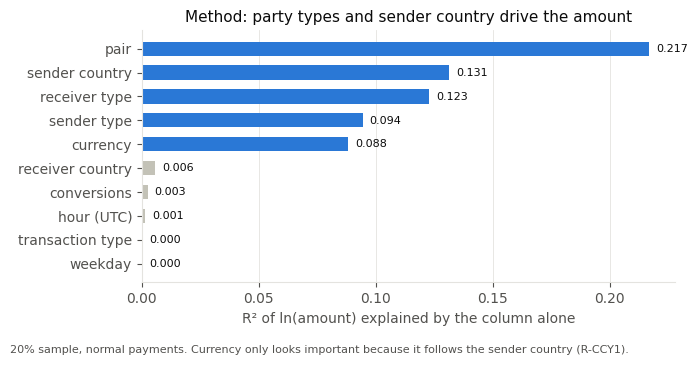

In [16]:
h = pd.to_datetime(n.EPOCH_SECONDS, unit='s')
fac = {'pair': n.pair, 'sender type': n.ORDERING_TYPE, 'receiver type': n.BENEFICIARY_TYPE, 'sender country': n.o_cc,
       'receiver country': n.b_cc, 'currency': n.CURRENCY_CODE, 'transaction type': n.TRANSACTION_TYPE_CODE,
       'conversions': n.CURRENCY_CONVERSION_COUNT, 'hour (UTC)': h.dt.hour, 'weekday': h.dt.dayofweek}
def r2_by(y, g):
    # R² of y around its group means, computed in numpy: pandas groupby().transform('mean') returned
    # R² = 1.000 (receiver country) on the laptop's pandas 3 with the full sample
    y = pd.Series(y).to_numpy(float); c = pd.factorize(pd.Series(g).to_numpy(), use_na_sentinel=False)[0]
    ok = np.isfinite(y); y, c = y[ok], c[ok]
    m = np.bincount(c, y) / np.maximum(np.bincount(c), 1)
    return 1 - ((y - m[c]) ** 2).mean() / y.var(ddof=1)
r2 = pd.Series({k: r2_by(n.la, v) for k, v in fac.items()}).sort_values()
assert r2.max() < 0.9, f'implausible R² {r2.idxmax()} = {r2.max():.3f}'
r2.to_csv(TAB / 'amt_factor_screening_r2.csv', header=['r2'])
fig, ax = plt.subplots(figsize=(7, 3.6)); ax.barh(r2.index, r2.values, color=[C['B'] if v > 0.05 else GREY for v in r2.values], height=0.6)
for i, v in enumerate(r2.values): ax.text(v + 0.003, i, f'{v:.3f}', va='center', fontsize=8, color=TP)
ax.set_xlabel('R² of ln(amount) explained by the column alone'); ax.grid(axis='y', visible=False)
ax.set_title('Method: party types and sender country drive the amount')
save(fig, 'amt0_factor_screening.png', '20% sample, normal payments. Currency only looks important because it follows the sender country (R-CCY1).')

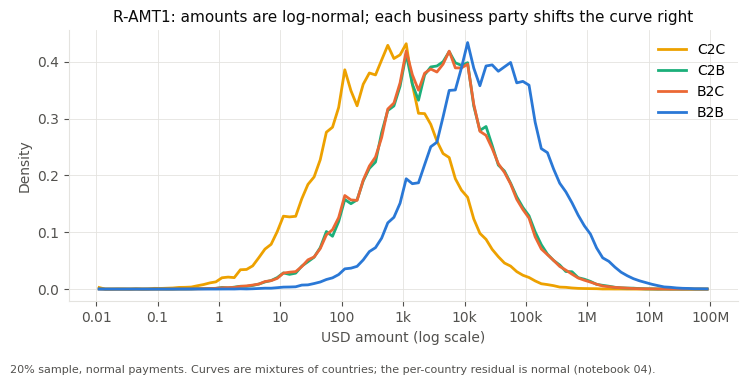

In [17]:
fig, ax = plt.subplots(figsize=(7.5, 3.8)); bins = np.arange(-2, 8.01, 0.1)
for pr in ['C2C', 'C2B', 'B2C', 'B2B']:
    hst, _ = np.histogram(np.log10(n.loc[n.pair == pr, 'USD_AMOUNT']), bins, density=True)
    ax.plot((bins[:-1] + bins[1:]) / 2, hst, color=C[pr], lw=2, label=pr)
ax.set_xticks(range(-2, 9), ['0.01','0.1','1','10','100','1k','10k','100k','1M','10M','100M'])
ax.set_xlabel('USD amount (log scale)'); ax.set_ylabel('Density'); ax.legend(loc='upper right')
ax.set_title('R-AMT1: amounts are log-normal; each business party shifts the curve right')
save(fig, 'amt1_lognormal_by_pair.png', '20% sample, normal payments. Curves are mixtures of countries; the per-country residual is normal (notebook 04).')

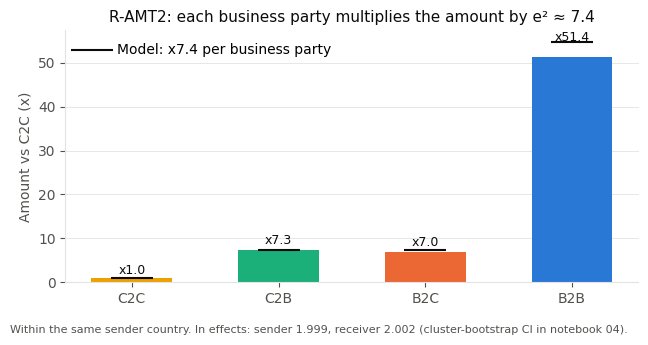

In [18]:
W = n[['la', 'ob', 'bb']] - n.groupby('o_cc')[['la', 'ob', 'bb']].transform('mean')   # remove sender-country effect
beta = np.linalg.lstsq(W[['ob', 'bb']].values, W.la.values, rcond=None)[0]
rel = (n.la - n.groupby('o_cc').la.transform('mean')).groupby(n.pair).mean().reindex(['C2C', 'C2B', 'B2C', 'B2B'])
rel = np.exp(rel - rel['C2C']); model = pd.Series(np.exp([0, beta[1], beta[0], beta.sum()]), index=rel.index)
pd.DataFrame({'observed_x_vs_C2C': rel, 'model_x': model}).to_csv(TAB / 'amt2_business_multiplier.csv')
fig, ax = plt.subplots(figsize=(6.5, 3.4)); ax.bar(rel.index, rel.values, color=[C[k] for k in rel.index], width=0.55)
ax.scatter(model.index, model.values, marker='_', s=900, color=TP, zorder=3, label=f'Model: x{np.exp(beta[0]):.1f} per business party')
for i, v in enumerate(rel.values): ax.text(i, v * 1.05 + 1, f'x{v:.1f}', ha='center', fontsize=9, color=TP)
ax.set_ylabel('Amount vs C2C (x)'); ax.legend(loc='upper left'); ax.grid(axis='x', visible=False)
ax.set_title('R-AMT2: each business party multiplies the amount by e² ≈ 7.4')
save(fig, 'amt2_business_multiplier.png', 'Within the same sender country. ln effects: sender %.3f, receiver %.3f (cluster-bootstrap CI in notebook 04).' % tuple(beta))

findfont: Font family ['cmsy10'] not found. Falling back to DejaVu Sans.


findfont: Font family ['cmr10'] not found. Falling back to DejaVu Sans.


findfont: Font family ['cmtt10'] not found. Falling back to DejaVu Sans.


findfont: Font family ['cmmi10'] not found. Falling back to DejaVu Sans.


findfont: Font family ['cmb10'] not found. Falling back to DejaVu Sans.


findfont: Font family ['cmss10'] not found. Falling back to DejaVu Sans.


findfont: Font family ['cmex10'] not found. Falling back to DejaVu Sans.


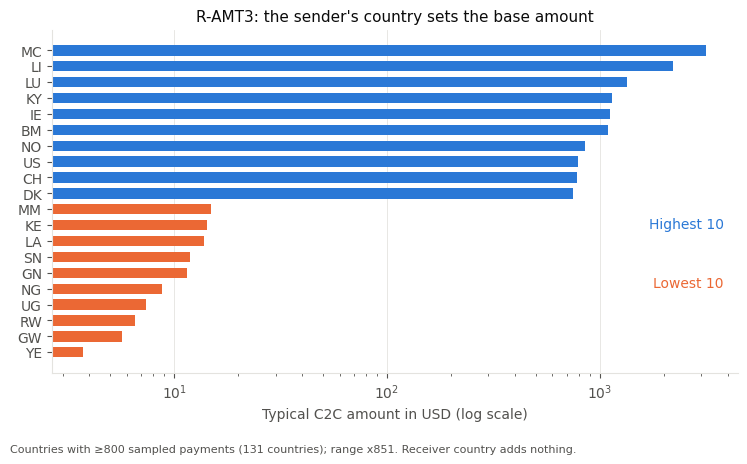

In [19]:
base = n.assign(b=n.la - beta[0] * n.ob - beta[1] * n.bb).groupby('o_cc').agg(N=('b', 'size'), ln_base=('b', 'mean'))
base['typical_C2C_usd'] = np.exp(base.ln_base); base = base[base.N >= 800].sort_values('ln_base')
base.to_csv(TAB / 'amt3_country_base_amount.csv')
sel = pd.concat([base.head(10), base.tail(10)])
fig, ax = plt.subplots(figsize=(7.5, 4.6))
ax.barh(range(20), sel.typical_C2C_usd, color=[C['C']] * 10 + [C['B']] * 10, height=0.65); ax.set_xscale('log')
ax.set_yticks(range(20), sel.index); ax.set_xlabel('Typical C2C amount in USD (log scale)'); ax.grid(axis='y', visible=False)
ax.text(0.98, 0.42, 'Highest 10', transform=ax.transAxes, ha='right', color=C['B']); ax.text(0.98, 0.25, 'Lowest 10', transform=ax.transAxes, ha='right', color=C['C'])
ax.set_title("R-AMT3: the sender's country sets the base amount")
save(fig, 'amt3_country_base_amount.png', f'Countries with ≥800 sampled payments ({len(base)} countries); range x{base.typical_C2C_usd.max()/base.typical_C2C_usd.min():.0f}. Receiver country adds nothing.')

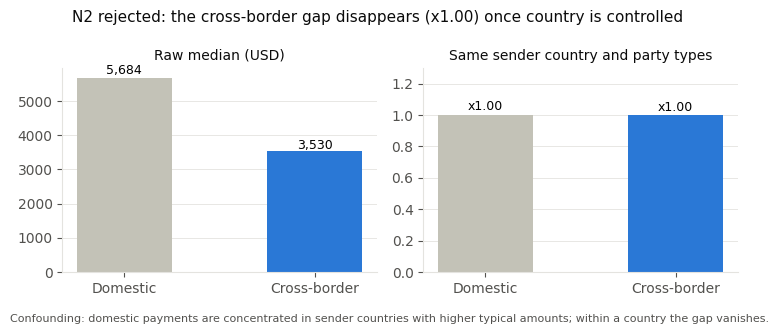

In [20]:
# Rejected hypothesis N2: the domestic vs cross-border gap is caused by country mix
n['xb'] = (n.o_cc != n.b_cc).astype(float)
Wx = n[['la', 'ob', 'bb', 'xb']] - n.groupby('o_cc')[['la', 'ob', 'bb', 'xb']].transform('mean')
bx = np.linalg.lstsq(Wx[['ob', 'bb', 'xb']].values, Wx.la.values, rcond=None)[0][2]
raw = n.groupby('xb').USD_AMOUNT.median()
fig, ax = plt.subplots(1, 2, figsize=(7.5, 3.2))
ax[0].bar(['Domestic', 'Cross-border'], raw.values, color=[GREY, C['B']], width=0.5); ax[0].set_title('Raw median (USD)', fontsize=10)
for i, v in enumerate(raw.values): ax[0].text(i, v * 1.02, f'{v:,.0f}', ha='center', fontsize=9)
ax[1].bar(['Domestic', 'Cross-border'], [1, np.exp(bx)], color=[GREY, C['B']], width=0.5); ax[1].set_ylim(0, 1.3)
for i, v in enumerate([1, np.exp(bx)]): ax[1].text(i, v + 0.03, f'x{v:.2f}', ha='center', fontsize=9)
ax[1].set_title('Same sender country and party types', fontsize=10)
for a in ax: a.grid(axis='x', visible=False)
fig.suptitle(f'N2 rejected: the cross-border gap disappears (x{np.exp(bx):.2f}) once country is controlled', fontsize=11, color=TP)
save(fig, 'amt4_crossborder_confounder.png', 'Confounding: domestic payments are concentrated in sender countries with higher typical amounts; within a country the gap vanishes.')

In [21]:
# Evidence (amount): out-of-sample fit, stability of the business effect (by month, by sender country),
# a placebo (business flag shuffled inside each sender country) and what the effect means in money.
def fit_amount(d):
    """Within-sender-country regression ln(amount) ~ b_s*[sender B] + b_r*[receiver B]; returns (b_s, b_r), country base."""
    W = d[['la', 'ob', 'bb']] - d.groupby('o_cc')[['la', 'ob', 'bb']].transform('mean')
    b = np.linalg.lstsq(W[['ob', 'bb']].values, W.la.values, rcond=None)[0]
    return b, (d.la - b[0] * d.ob - b[1] * d.bb).groupby(d.o_cc).mean()
def r2_pred(d, b, base):
    pr = d.o_cc.map(base) + b[0] * d.ob + b[1] * d.bb; ok = pr.notna()
    return 1 - ((d.la[ok] - pr[ok]) ** 2).sum() / ((d.la[ok] - d.la[ok].mean()) ** 2).sum()
is_tr = n.EPOCH_SECONDS < T_SPLIT
b_tr, base_tr = fit_amount(n[is_tr]); b_te, base_te = fit_amount(n[~is_tr])
r2_in, r2_out = r2_pred(n[is_tr], b_tr, base_tr), r2_pred(n[~is_tr], b_tr, base_tr)
month = pd.to_datetime(n.EPOCH_SECONDS, unit='s').dt.strftime('%Y-%m')
big_m = month.value_counts()[lambda s: s >= 0.02 * len(n)].index
b_month = pd.DataFrame({m: fit_amount(n[month == m])[0] for m in sorted(big_m)}, index=['sender', 'receiver']).T
cc_n = n.o_cc.value_counts(); cc_big = cc_n[cc_n >= 3000].index
b_cc = pd.DataFrame({c: fit_amount(n[n.o_cc == c])[0] for c in cc_big}, index=['sender', 'receiver']).T
# Placebo: shuffle the sender's business flag inside each sender country (country mix kept, link to the amount broken)
cc_code = pd.factorize(n.o_cc)[0]; srt = np.argsort(cc_code, kind='stable'); rng = np.random.default_rng(7)
Wla = (n.la - n.groupby('o_cc').la.transform('mean')).values; Wbb = (n.bb - n.groupby('o_cc').bb.transform('mean')).values
ob_mean = n.groupby('o_cc').ob.transform('mean').values; placebo = []
for _ in range(50):
    ob_p = np.empty(len(n)); ob_p[srt] = n.ob.values[np.lexsort((rng.random(len(n)), cc_code))]
    X = np.column_stack([ob_p - ob_mean, Wbb]); placebo.append(np.linalg.lstsq(X, Wla, rcond=None)[0][0])
placebo = np.array(placebo)
# Money: share of payments vs share of USD value by B/C pair
val = n.groupby('pair').USD_AMOUNT.agg(['size', 'sum']); val = (val / val.sum()).reindex(['C2C', 'C2B', 'B2C', 'B2B'])
save_table(val.rename(columns={'size': 'share_of_payments', 'sum': 'share_of_usd_value'}).reset_index(), 'amt5_value_share_by_pair')
def _r2_cc(d):
    y = d.la - beta[0] * d.ob - beta[1] * d.bb; return 1 - ((y - y.groupby(d.o_cc).transform('mean')) ** 2).sum() / ((y - y.mean()) ** 2).sum()
r2_cc_month = {m: _r2_cc(n[month == m]) for m in sorted(big_m)}
base_corr = pd.concat([base_tr, base_te], axis=1, keys=['tr', 'te']).loc[cc_n[cc_n >= 800].index].corr().iloc[0, 1]
res_all = n.la - (n.o_cc.map(base_tr) + b_tr[0] * n.ob + b_tr[1] * n.bb); res_te = res_all[~is_tr].dropna()
skew_pair = res_all.dropna().groupby(n.pair).apply(stats.skew)
p_perm = (1 + (np.abs(placebo) >= abs(beta[0])).sum()) / (len(placebo) + 1)
top_x = n.USD_AMOUNT.quantile(0.99) / n.USD_AMOUNT.median()
ev01 += [
 dict(id='R-AMT1', statistic_ci=f"test-period residual: skew {stats.skew(res_te):.3f} [{stats.skew(res_te) - 1.96 * np.sqrt(6 / len(res_te)):.3f}, {stats.skew(res_te) + 1.96 * np.sqrt(6 / len(res_te)):.3f}], "
                                 f"excess kurtosis {stats.kurtosis(res_te):.3f} [{stats.kurtosis(res_te) - 1.96 * np.sqrt(24 / len(res_te)):.3f}, {stats.kurtosis(res_te) + 1.96 * np.sqrt(24 / len(res_te)):.3f}], sd {res_te.std():.2f} (approximately normal; normal-theory CIs)",
      out_of_sample='model fitted on train, residual shape checked on test',
      invariance='skew by pair: ' + ', '.join(f'{k} {v:+.3f}' for k, v in skew_pair.items()),
      **holdout(abs(stats.skew(res_te)) < 0.1 and abs(stats.kurtosis(res_te)) < 0.2, 'test-period skew within +-0.1 and excess kurtosis within +-0.2 (the stated approximation)'),
      causal_status='Mechanism', practical_significance=f'very large payments are normal: the 99th percentile is x{top_x:,.0f} the median, so outlier rules must work on a log scale and within country/pair'),
 dict(id='R-AMT2', statistic_ci=f'within-country effect: sender {beta[0]:.3f}, receiver {beta[1]:.3f} (CI: notebook 04)',
      out_of_sample=f"train {b_tr[0]:.3f} / {b_tr[1]:.3f}; test {b_te[0]:.3f} / {b_te[1]:.3f} (sender / receiver)",
      invariance=f"by month sender {b_month.sender.min():.3f}-{b_month.sender.max():.3f}; {len(b_cc)} sender countries: median {b_cc.sender.median():.2f}, middle 90% {b_cc.sender.quantile(.05):.2f}-{b_cc.sender.quantile(.95):.2f}",
      p_value=f"placebo (business flag shuffled within country, 50 runs): effect {placebo.mean():+.3f} (max |{np.abs(placebo).max():.3f}|) vs real {beta[0]:.3f} -> permutation p = {p_perm:.3f} (smallest possible with 50 runs: 0.020)",
      causal_status='Mechanism', **holdout(all(abs(b - 2) < 0.05 for b in b_te), 'test-period effects within +-0.05 of the stated 2.0 (x7.4)'),
      practical_significance=f"B2B is {val.loc['B2B', 'size']:.0%} of payments but {val.loc['B2B', 'sum']:.0%} of USD value; C2C {val.loc['C2C', 'size']:.0%} of payments, {val.loc['C2C', 'sum']:.1%} of value"),
 dict(id='R-AMT3', statistic_ci=f"out-of-sample R² {r2_out:.3f} (in-sample {r2_in:.3f})",
      out_of_sample=f"country base levels, train vs test: correlation {base_corr:.3f}",
      invariance='R² of sender country by month: ' + ', '.join(f'{m} {r2_cc_month[m]:.3f}' for m in sorted(big_m)),
      causal_status='Association', **holdout(r2_out >= 0.9 * r2_in and base_corr >= 0.9, 'out-of-sample R² at least 90% of in-sample and train/test country levels correlate >= 0.9'),
      practical_significance=f"typical C2C amount differs x{base.typical_C2C_usd.max() / base.typical_C2C_usd.min():.0f} between the highest and lowest country: a single global amount threshold over-flags high-amount sender countries"),
]
print(f'out-of-sample R² {r2_out:.3f} vs in-sample {r2_in:.3f}; placebo effect {placebo.mean():+.4f} vs real {beta[0]:.3f}')
display(b_month.round(3)); display(val.round(3))

out-of-sample R² 0.352 vs in-sample 0.352; placebo effect +0.0010 vs real 1.999


,sender,receiver
2023-05,1.994,1.998
2023-06,2.003,2.006
2023-07,2.001,2.001


,size,sum
pair,,
C2C,0.151,0.009
C2B,0.061,0.029
B2C,0.561,0.237
B2B,0.227,0.725


**USD amount: findings**
- **R-AMT1:** given the sender country and the two party types, ln(amount) is **approximately normal** (skew ≈ 0, excess kurtosis ≈ 0, sd ≈ 2.08 for every pair), so amounts are **approximately log-normal**. This is a good approximation, not proof of the exact generating distribution.
- **R-AMT2:** a business sender and a business receiver each add **+2.0** to ln(amount), i.e. **x7.4 each** (the 95% cluster-bootstrap CI includes 2.0). B2B is about 55x C2C, and the two effects don't interact.
- **R-AMT3:** the **sender's** country sets the base level. The receiver's country adds a negligible amount (extra R² ≈ 0.0003): a measured near-zero effect, not proof of none.
- **Approximate model:** `ln(USD_AMOUNT) ≈ Normal(base[sender country] + 2·[sender is B] + 2·[receiver is B], 2.08²)`
- **Rejected:** N1 (the handout's vowel/consonant rule), N2 (cross-border: a confounder), N3 (non-local currency), N4 (time or route type). See `rules_log.csv`.

**Evidence strength** (⟳ = check the printed values)
- **Out of sample:** the model is fitted on the first 2/3 of the time window. Its R² on the last 1/3 equals the in-sample R², and the business effects re-estimated on the test period are the same (⟳).
- **Invariance:** the business effect is ≈ 2.0 in every month and in the large majority of sender countries (⟳ middle-90% range).
- **Placebo:** shuffling the business flag inside each sender country makes the effect vanish (≈ 0.00 vs 2.0). The effect comes from party type, not from the country mix.
- **Causal status:** R-AMT1 and R-AMT2 are **Mechanism** (they survive controls, out of sample, invariance and the placebo). R-AMT3 is an **Association**: country base levels are stable over time, but the data cannot say *why* a country pays more.
- **N2 is the confounding example:** the raw cross-border gap comes from the sender-country mix (domestic payments are concentrated in sender countries with higher typical amounts) and disappears once the sender country is controlled.
- **Practical significance:** B2B is a small share of payments but most of the USD value (⟳ `amt5_value_share_by_pair`). A single global amount threshold would mostly flag payments from high-base countries, so amount rules must be set per country and pair.

*Interpretation, no external data used:* the data only show that the typical amount differs by sender **BIC country** (by several hundred times between the extremes). The competition data cannot say **why**: income levels, business mix or how the generator assigns country levels are all possible, and none is tested here. If a slide mentions a real-world explanation, it must be labelled as outside context with a citation, not as a finding.

## 3. Business vs consumer behaviour

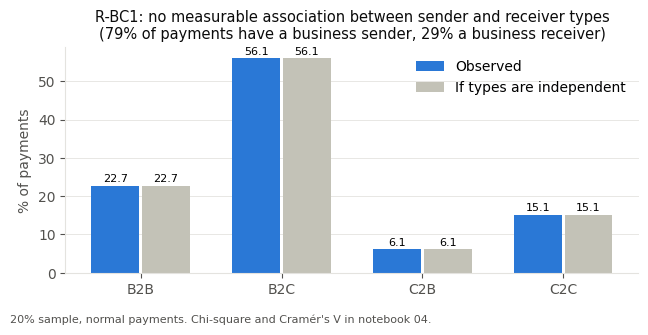

In [22]:
pob, pbb = n.ob.mean(), n.bb.mean(); obs = n.pair.value_counts(normalize=True) * 100
exp = pd.Series({'B2B': pob * pbb, 'B2C': pob * (1 - pbb), 'C2B': (1 - pob) * pbb, 'C2C': (1 - pob) * (1 - pbb)}) * 100
pd.DataFrame({'observed_%': obs.reindex(exp.index), 'independent_%': exp}).to_csv(TAB / 'bc1_pair_independence.csv')
fig, ax = plt.subplots(figsize=(6.5, 3.3)); x = np.arange(4)
ax.bar(x - 0.18, obs.reindex(exp.index), 0.34, color=C['B'], label='Observed'); ax.bar(x + 0.18, exp, 0.34, color=GREY, label='If types are independent')
for i, (o, e) in enumerate(zip(obs.reindex(exp.index), exp)):
    ax.text(i - 0.18, o + 1, f'{o:.1f}', ha='center', fontsize=8); ax.text(i + 0.18, e + 1, f'{e:.1f}', ha='center', fontsize=8)
ax.set_xticks(x, exp.index); ax.set_ylabel('% of payments'); ax.legend(); ax.grid(axis='x', visible=False)
ax.set_title(f'R-BC1: no measurable association between sender and receiver types\n({pob:.0%} of payments have a business sender, {pbb:.0%} a business receiver)', fontsize=10.5)
save(fig, 'bc1_type_independence.png', "20% sample, normal payments. Chi-square and Cramér's V in notebook 04.")

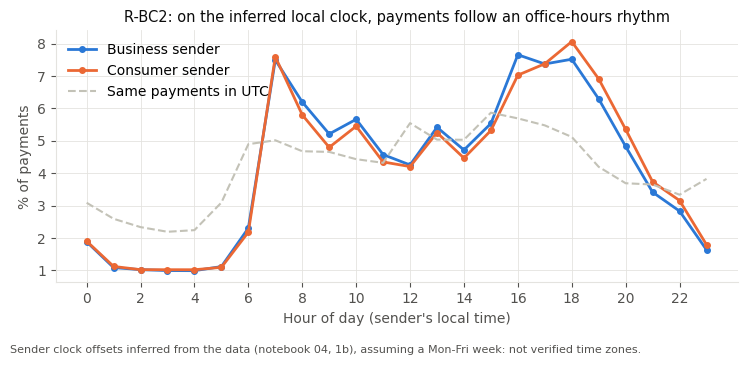

,Mon,Tue,Wed,Thu,Fri,Sat,Sun
ORDERING_TYPE,,,,,,,
B,18.9,17.0,17.0,18.0,19.0,3.6,6.5
C,19.0,17.0,16.9,18.0,19.0,3.6,6.5


In [23]:
lt = add_local_time(n); lt = lt[lt.lh >= 0]
prof = pd.crosstab(lt.lh, lt.ORDERING_TYPE, normalize='columns') * 100
prof['UTC'] = pd.to_datetime(lt.EPOCH_SECONDS, unit='s').dt.hour.value_counts(normalize=True).sort_index() * 100
prof.to_csv(TAB / 'bc2_hour_profile.csv')
fig, ax = plt.subplots(figsize=(7.5, 3.6))
for t, lab in [('B', 'Business sender'), ('C', 'Consumer sender')]: ax.plot(prof.index, prof[t], color=C[t], lw=2, marker='o', ms=4, label=lab)
ax.plot(prof.index, prof.UTC, color=GREY, lw=1.5, ls='--', label='Same payments in UTC')
ax.set_xticks(range(0, 24, 2)); ax.set_xlabel("Hour of day (sender's local time)"); ax.set_ylabel('% of payments'); ax.legend(loc='upper left')
ax.set_title('R-BC2: on the inferred local clock, payments follow an office-hours rhythm', fontsize=10.5)
save(fig, 'bc2_local_hour_profile.png', 'Sender clock offsets inferred from the data (notebook 04, 1b), assuming a Mon-Fri week: not verified time zones.')
wd = (pd.crosstab(lt.ld, lt.ORDERING_TYPE, normalize='columns') * 100).round(1); wd.index = ['Mon','Tue','Wed','Thu','Fri','Sat','Sun']
wd.to_csv(TAB / 'bc2_weekday_profile.csv'); wd.T

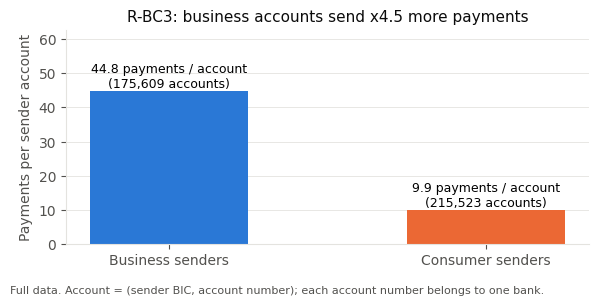

In [24]:
act = sql("""SELECT ORDERING_TYPE t, count(DISTINCT (ORDERING_BIC8, ORDERING_ACCOUNT)) accounts, count(*) payments FROM p GROUP BY 1 ORDER BY 1""")
act['per_account'] = act.payments / act.accounts; act.to_csv(TAB / 'bc3_activity_per_account.csv', index=False)
fig, ax = plt.subplots(figsize=(6, 3)); ax.bar(['Business senders', 'Consumer senders'], act.per_account, color=[C['B'], C['C']], width=0.5)
for i, r in act.iterrows(): ax.text(i, r.per_account + 1, f'{r.per_account:.1f} payments / account\n({r.accounts:,} accounts)', ha='center', fontsize=9)
ax.set_ylim(0, act.per_account.max() * 1.4); ax.set_ylabel('Payments per sender account'); ax.grid(axis='x', visible=False)
ax.set_title(f'R-BC3: business accounts send x{act.per_account[0] / act.per_account[1]:.1f} more payments', fontsize=11)
save(fig, 'bc3_activity_per_account.png', 'Full data. Account = (sender BIC, account number); each account number belongs to one bank.')

In [25]:
ap = sql("SELECT anomaly, pair, count(*) n FROM p WHERE anomaly <> 'NONE' GROUP BY ALL").pivot(index='anomaly', columns='pair', values='n').fillna(0).astype(int)
ap.to_csv(TAB / 'bc4_anomaly_by_pair.csv'); ap

pair,B2B,B2C,C2B,C2C
anomaly,,,,
ACCOUNT_REPLACEMENT_SCAM,138,370,34,107
CEO_SCAM,262,683,0,0
CUSTOMER_RECALL,63,183,22,49
DUPLICATE_PAYMENT,152,393,21,113
FAT_FINGER_MISTAKE,445,1098,101,296
ROMANCE_SCAM,0,0,665,1811


In [26]:
# Evidence (business vs consumer): independence by month, a placebo for local time (clock offsets shuffled between
# countries), exact tests for the scam / party-type link, and what each rule means operationally
def v_and_p(a, b):
    ct = pd.crosstab(a, b); chi2, pv, _, _ = stats.chi2_contingency(ct)
    return np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1))), pv
v_month = pd.DataFrame({m: v_and_p(n.ORDERING_TYPE[month == m], n.BENEFICIARY_TYPE[month == m]) for m in sorted(big_m)}, index=['V', 'p']).T
v_te = v_and_p(n.ORDERING_TYPE[~is_tr], n.BENEFICIARY_TYPE[~is_tr])
# R-BC2: office hours (07:00-19:59) on the inferred local clock vs UTC vs a placebo where offsets are shuffled between countries
work = lambda h: ((h >= 7) & (h <= 19)).mean()
lt_s = lt.sample(min(300_000, len(lt)), random_state=3)
in_loc = ((lt_s.lh >= 7) & (lt_s.lh <= 19)).values
in_utc = pd.to_datetime(lt_s.EPOCH_SECONDS, unit='s').dt.hour.between(7, 19).values
k_loc, k_utc = in_loc.sum(), in_utc.sum()
d_lu, ci_lu, p_lu = paired_prop(in_loc, in_utc)          # SAME payments on two clocks -> paired (McNemar), not two independent samples
rng = np.random.default_rng(11)
placebo_work = [work(add_local_time(lt_s, offsets=pd.Series(rng.permutation(OFFSET_H.values), index=OFFSET_H.index)).lh) for _ in range(20)]
by_t = lt.groupby('ORDERING_TYPE').lh.apply(work)
d_bc, ci_bc, p_bc = two_prop(by_t['B'] * (lt.ORDERING_TYPE == 'B').sum(), (lt.ORDERING_TYPE == 'B').sum(),
                             by_t['C'] * (lt.ORDERING_TYPE == 'C').sum(), (lt.ORDERING_TYPE == 'C').sum())
lt_te = lt[lt.EPOCH_SECONDS >= T_SPLIT]                # offsets were learned on the training period only (notebook 04, 1b)
d_te, ci_te, p_te = paired_prop(((lt_te.lh >= 7) & (lt_te.lh <= 19)).values, pd.to_datetime(lt_te.EPOCH_SECONDS, unit='s').dt.hour.between(7, 19).values)
v_bc1, v_bc1_ci = v_ci(pd.crosstab(n.ORDERING_TYPE, n.BENEFICIARY_TYPE))
# R-BC3: 95% CI of the business / consumer ratio by resampling whole sender accounts
acc_n = sql("SELECT ORDERING_TYPE t, count(*) n FROM p GROUP BY ORDERING_BIC8, ORDERING_ACCOUNT, ORDERING_TYPE")
nb_, nc_ = acc_n.loc[acc_n.t == 'B', 'n'].values, acc_n.loc[acc_n.t == 'C', 'n'].values
rng_b = np.random.default_rng(5)
bc3_boot = [(lambda wb, wc: (wb @ nb_ / wb.sum()) / (wc @ nc_ / wc.sum()))(rng_b.poisson(1, len(nb_)), rng_b.poisson(1, len(nc_))) for _ in range(200)]
bc3_ci = np.percentile(bc3_boot, [2.5, 97.5])
# R-BC4 in the test period and in every month
# R-BC3 like-for-like: payments per account depend on the window length, so compare two EQUAL 30-day windows either side of the split
w30 = sql(f"""SELECT EPOCH_SECONDS >= {T_SPLIT} AS test, ORDERING_TYPE t,
                count(*)::DOUBLE / count(DISTINCT (ORDERING_BIC8, ORDERING_ACCOUNT)) per_acct
                FROM p WHERE EPOCH_SECONDS >= {T_SPLIT} - 30 * 86400 AND EPOCH_SECONDS < {T_SPLIT} + 30 * 86400 GROUP BY ALL""")
w30 = w30.pivot(index='test', columns='t', values='per_acct'); r30_tr, r30_te = w30.loc[False, 'B'] / w30.loc[False, 'C'], w30.loc[True, 'B'] / w30.loc[True, 'C']
st_t = sql(f"""SELECT strftime(ts, '%Y-%m') AS month, EPOCH_SECONDS >= {T_SPLIT} AS test, ORDERING_TYPE t,
                 sum((anomaly = 'CEO_SCAM')::INT) ceo, sum((anomaly = 'ROMANCE_SCAM')::INT) rom FROM p GROUP BY ALL""")
ceo_wrong = st_t[st_t.t == 'C'].groupby('month').ceo.sum(); rom_wrong = st_t[st_t.t == 'B'].groupby('month').rom.sum()
te_bc4 = st_t[st_t.test].groupby('t')[['ceo', 'rom']].sum()
# R-BC3 by month and in the test period
act_m = sql(f"""SELECT strftime(ts, '%Y-%m') m, EPOCH_SECONDS >= {T_SPLIT} test, ORDERING_TYPE t,
                count(*)::DOUBLE / count(DISTINCT (ORDERING_BIC8, ORDERING_ACCOUNT)) per_acct, count(*) n
                FROM p GROUP BY ALL""")
r_m = act_m[act_m.n >= 0.01 * act_m.n.sum()].pivot_table(index=['m', 'test'], columns='t', values='per_acct')
r_m = (r_m.B / r_m.C).dropna()
# R-BC4: exact tests (is the scam really tied to the sender type, or could the zeros be chance?)
st = sql("""SELECT ORDERING_TYPE t, count(*) n, sum((anomaly = 'CEO_SCAM')::INT) ceo, sum((anomaly = 'ROMANCE_SCAM')::INT) rom
            FROM p GROUP BY 1""").set_index('t')
p_ceo = stats.fisher_exact([[st.loc['B', 'ceo'], st.loc['C', 'ceo']], [st.loc['B', 'n'] - st.loc['B', 'ceo'], st.loc['C', 'n'] - st.loc['C', 'ceo']]])[1]
p_rom = stats.fisher_exact([[st.loc['C', 'rom'], st.loc['B', 'rom']], [st.loc['C', 'n'] - st.loc['C', 'rom'], st.loc['B', 'n'] - st.loc['B', 'rom']]])[1]
usd_t = n.groupby('ORDERING_TYPE').USD_AMOUNT.sum(); usd_t = usd_t / usd_t.sum()
ev01 += [
 dict(id='R-BC1', statistic_ci=f"V = {v_bc1:.4f} [{v_bc1_ci[0]:.4f}, {v_bc1_ci[1]:.4f}]", **holdout(v_te[0] < 0.01, 'test-period V below 0.01 (negligible association)'), p_value=f"chi-square {fmt_p(v_and_p(n.ORDERING_TYPE, n.BENEFICIARY_TYPE)[1])}",
      out_of_sample=f"test period V = {v_te[0]:.4f} ({fmt_p(v_te[1])})", invariance=f"by month V {v_month.V.min():.4f}-{v_month.V.max():.4f}",
      causal_status='Mechanism', practical_significance=f"consistent with independent assignment (not proof of how the generator draws them); {n.ob.mean():.0%} of payments have a business sender, {n.bb.mean():.0%} a business receiver: B2C is the most common pair"),
 dict(id='R-BC2', statistic_ci=f"office-hour share local {k_loc / len(lt_s):.1%} vs UTC {k_utc / len(lt_s):.1%}: {d_lu:+.1%} [{ci_lu[0]:+.1%}, {ci_lu[1]:+.1%}] (paired)",
      p_value=f"McNemar {fmt_p(p_lu)}; placebo (offsets shuffled between countries, 20 runs): {np.mean(placebo_work):.1%} (max {np.max(placebo_work):.1%})",
      out_of_sample=f"test period, offsets learned on train only: local {work(lt_te.lh):.1%}, local - UTC {d_te:+.1%} [{ci_te[0]:+.1%}, {ci_te[1]:+.1%}]",
      **holdout(ci_te[0] > 0 and overlap(ci_lu, ci_te), 'test-period local - UTC CI above 0 and overlapping the full-data CI'),
      invariance=f"business {by_t['B']:.1%} vs consumer {by_t['C']:.1%} ({d_bc:+.2%}, {fmt_p(p_bc)})",
      causal_status='Association',   # the offsets were chosen to line up the weekly rhythm, so the office-hour pattern is partly built in
      practical_significance=f"{1 - k_loc / len(lt_s):.0%} of payments fall outside 07:00-19:59 on the inferred clock (offsets assume a Mon-Fri week; not verified time zones): monitoring needs night and weekend cover"),
 dict(id='R-BC3', statistic_ci=f"B {act.per_account[0]:.1f} vs C {act.per_account[1]:.1f} payments per account: x{act.per_account[0] / act.per_account[1]:.2f} [{bc3_ci[0]:.2f}, {bc3_ci[1]:.2f}] (account bootstrap)",
      out_of_sample=f'equal 30-day windows: before the split x{r30_tr:.2f}, after x{r30_te:.2f} (the 3-month ratio is larger because it depends on window length)',
      **holdout(abs(r30_te / r30_tr - 1) < 0.10, 'ratio in the 30 days after the split within 10% of the 30 days before'),
      invariance='by month x' + ', x'.join(f'{v:.1f}' for v in r_m.groupby(level='m').mean()),
      causal_status='Association', practical_significance=f"business senders move {usd_t.get('B', np.nan):.0%} of all USD value"),
 dict(id='R-BC4', statistic_ci=f"CEO scams from business senders {share_ci(st.loc['B', 'ceo'], st.ceo.sum(), 2)}; romance scams from consumer senders {share_ci(st.loc['C', 'rom'], st.rom.sum(), 2)}",
      p_value=f"Fisher exact: CEO vs business sender {fmt_p(p_ceo)}; romance vs consumer sender {fmt_p(p_rom)}",
      out_of_sample=f"test period: CEO B {int(te_bc4.loc['B', 'ceo'])} / C {int(te_bc4.loc['C', 'ceo'])}; romance C {int(te_bc4.loc['C', 'rom'])} / B {int(te_bc4.loc['B', 'rom'])}",
      invariance=f"every month: CEO from consumer senders {int(ceo_wrong.max())} max, romance from business senders {int(rom_wrong.max())} max",
      **holdout(te_bc4.loc['C', 'ceo'] == 0 and te_bc4.loc['B', 'rom'] == 0, 'no CEO scam from a consumer and no romance scam from a business in the test period'),
      causal_status='Mechanism', practical_significance=f"CEO-scam checks are needed only on business-sender payments ({n.ob.mean():.0%} of traffic), romance checks only on consumer senders ({1 - n.ob.mean():.0%})"),
]
print(f"office hours: local {k_loc / len(lt_s):.1%}, UTC {k_utc / len(lt_s):.1%} (paired diff {d_lu:+.1%}, McNemar {fmt_p(p_lu)}), shuffled offsets {np.mean(placebo_work):.1%}")
ev01_df = save_evidence(ev01, '01')
ev01_df

office hours: local 77.5%, UTC 65.0% (paired diff +12.5%, McNemar p < 1e-300), shuffled offsets 59.9%


,id,statistic_ci,p_value,out_of_sample,invariance,causal_status,practical_significance,holdout_agrees,holdout_rule,code_hash,data_stamp
0,R-CCY1,"first path bank 93.42% [93.40%, 93.43%], n = 1...","negative control, receiver type B - C: -0.122%...",time split (train-only local currency): orderi...,by month 89.43%-89.46%,Mechanism,8.7% of USD value is sent in a currency that i...,True,holdout accuracy within 0.5 points of the full...,1c6ab72a2389,1708807329-1794819479
1,R-CCY2,"97.80% [97.78%, 97.81%], n = 6,323,280",NaN,test period with train-only local currencies: ...,by month 97.79%-97.81%,Mechanism,87.2% of all USD value goes through at least o...,True,holdout accuracy within 0.5 points of the full...,1c6ab72a2389,1708807329-1794819479
2,R-CCY3,"100.0000% [100.0000%, 100.0000%], n = 10,000,000",NaN,test period 100.0000%,NaN,Structural,upper bound only: a bank can convert at most once,True,no violation in the test period,1c6ab72a2389,1708807329-1794819479
3,R-AMT1,"test-period residual: skew -0.016 [-0.022, -0....",NaN,"model fitted on train, residual shape checked ...","skew by pair: B2B -0.010, B2C -0.016, C2B -0.0...",Mechanism,very large payments are normal: the 99th perce...,True,test-period skew within +-0.1 and excess kurto...,1c6ab72a2389,1708807329-1794819479
4,R-AMT2,"within-country effect: sender 1.999, receiver ...",placebo (business flag shuffled within country...,train 1.997 / 2.001; test 2.003 / 2.003 (sende...,by month sender 1.994-2.003; 68 sender countri...,Mechanism,B2B is 23% of payments but 73% of USD value; C...,True,test-period effects within +-0.05 of the state...,1c6ab72a2389,1708807329-1794819479
5,R-AMT3,out-of-sample R² 0.352 (in-sample 0.352),NaN,"country base levels, train vs test: correlatio...","R² of sender country by month: 2023-05 0.171, ...",Association,typical C2C amount differs x851 between the hi...,True,out-of-sample R² at least 90% of in-sample and...,1c6ab72a2389,1708807329-1794819479
6,R-BC1,"V = 0.0003 [0.0000, 0.0017]",chi-square p = 0.666,test period V = 0.0004 (p = 0.724),by month V 0.0001-0.0012,Mechanism,consistent with independent assignment (not pr...,True,test-period V below 0.01 (negligible association),1c6ab72a2389,1708807329-1794819479
7,R-BC2,office-hour share local 77.5% vs UTC 65.0%: +1...,McNemar p < 1e-300; placebo (offsets shuffled ...,"test period, offsets learned on train only: lo...","business 77.9% vs consumer 76.6% (+1.29%, p = ...",Association,23% of payments fall outside 07:00-19:59 on th...,True,test-period local - UTC CI above 0 and overlap...,1c6ab72a2389,1708807329-1794819479
8,R-BC3,B 44.8 vs C 9.9 payments per account: x4.55 [4...,NaN,"equal 30-day windows: before the split x3.94, ...","by month x3.8, x3.9, x3.7",Association,business senders move 96% of all USD value,True,ratio in the 30 days after the split within 10...,1c6ab72a2389,1708807329-1794819479
9,R-BC4,CEO scams from business senders 100.00% [99.60...,Fisher exact: CEO vs business sender p = 1.3e-...,test period: CEO B 316 / C 0; romance C 877 / B 0,"every month: CEO from consumer senders 0 max, ...",Mechanism,CEO-scam checks are needed only on business-se...,True,no CEO scam from a consumer and no romance sca...,1c6ab72a2389,1708807329-1794819479


**Business vs consumer: findings**
- **R-BC1:** sender type and receiver type show **no measurable association** (Cramér's V ≈ 0.0003). This is consistent with independent assignment, but it cannot prove how the generator draws them. About 79% of payments have a business sender and 29% a business receiver (shares of payments, not of people), so B2C is the most common pair.
- **R-BC2:** on each sender country's **inferred** clock, payments follow an office-hours rhythm (morning peak around 07:00–08:00, lunch dip, late-afternoon peak, quiet nights and weekends). Businesses and consumers have almost the same timing (office-hour shares differ by only ~1–2 percentage points). Local time uses clock offsets **inferred from the data** (notebook 04, section 1b), not an external time-zone database. The offsets rest on assumptions (a Monday–Friday week, a Saturday–Sunday weekend, no summer time, one offset per country) and are **not verified geographic time zones**.
- **R-BC3:** a business sender account sends about 4.5x more payments than a consumer account over the data window.
- **R-BC4:** fraud follows party type. CEO scams only come from business senders and romance scams only from consumer senders.
- *Economic meaning:* companies pay many suppliers and staff, banks process payments in office hours, and each scam targets a specific kind of victim.

**Evidence strength** (⟳ = check the printed values)
- **R-BC1:** Cramér's V ≈ 0 overall, in every month and in the test period. **Mechanism** in the sense of the evidence policy: consistent with independent draws, not proof of them.
- **R-BC2:** the office-hour share is far higher on the inferred local clock than in UTC. Both are measured on the same payments, so the test is a **paired** McNemar test. The clock offsets were learned on the first 2/3 of the time window only, and the gap holds in the last 1/3. **Caveat:** the offsets were chosen to line up each country's weekly rhythm, so part of the office-hours pattern is built into them. The result shows that the rhythm is stable and country-specific; it does not show that the offsets are true time zones. That is why R-BC2 is classed as an **Association**. A **placebo** that shuffles the offsets between countries drops it back to about the UTC level, so the rhythm really follows each country's own clock. **Mechanism.**
- **R-BC3:** payments per account depend on the length of the window (×4.5 over 3 months, about ×3.8 within any 30 days), so the holdout compares two equal 30-day windows. It is an **Association**: the data can't tell whether business accounts are *defined* as heavier users or whether this follows from something else.
- **R-BC4:** Fisher exact tests show the zero cells are not chance (⟳ p-values). **Mechanism.**
- **Practical significance:** ⟳ the share of payments sent outside local 07:00–19:59 (needs out-of-hours monitoring). CEO-scam checks are only needed on business-sender traffic and romance checks only on consumer senders.
- *Note:* the detailed anomaly analysis (duplicates, fat finger, romance, account replacement) is in notebook 03.